# Instructions for Assignment

Welcome to the Assignment! In this assignment, you will use the Iris dataset to solve the given questions. Please follow these instructions carefully to complete your assignment:

1. **Understand the Dataset**: The dataset used in this assignment is the Iris dataset, which contains measurements of iris flowers from three different species. Familiarize yourself with the dataset’s structure and columns before starting.

2. **Read Each Question Carefully**: Each question in this assignment is designed to test ebility in all the topics. Make sure to understand what is being asked before you start coding.

3. **Write Your Code in the Provided Cells**: For each question, a code cells is provided where you should write your solutions. Do not modify any other cells or sections of the notebook.

4. **Run Your Code**: After writing your code, run each cell to ensure that your solution works as expected. Verify that the plots match the requirements specified in the question.

5. **Debug if Necessary**: If your plots do not appear as expected, review your code and make any necessary corrections. You may use additional code cells for debugging, but make sure to remove or comment out these extra cells before submission.

6. **Complete All Questions**: Ensure that you address all the questions provided. Each question tests a different aspect of topic, so be sure to complete each one.

7. **Review Your Work**: Before submitting, double-check that all plots are correctly labeled and that the code runs without errors. Ensure that each plot is displayed as required.

8. **Download Your Notebook**: Once you have completed all the questions and verified that your solutions are correct, download your notebook file (.ipynb). You can do this by selecting `File` > `Download` > `Download .ipynb` from the Google Colab menu.

9. **Submit Your Assignment**: Upload the downloaded .ipynb file to the designated learning platform for submission.

10. **Verify Submission**: Ensure that you have uploaded the correct file and that it is not corrupted. If there are any issues with the file, you may need to resubmit.

---

Good luck with the assignment!

### Initial Setup
Execute the below code cell for initial setup

In [46]:
# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# Load the Iris dataset using seaborn
data = sns.load_dataset('iris')

# Display the first few rows of the dataset
data.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Q1. Create a pivot table showing the mean sepal_length for each species and Petal Size Category.

In [47]:
# Write the code here
# Create the 'Petal Size Category' column
median_petal_length = data['petal_length'].median()
data['Petal Size Category'] = data['petal_length'].apply(lambda x: 'Large Petals' if x > median_petal_length else 'Small Petals')

# Create the pivot table
pivot_table = pd.pivot_table(data, values='sepal_length', index='species',
                             columns='Petal Size Category', aggfunc='mean')
print(pivot_table)

Petal Size Category  Large Petals  Small Petals
species                                        
setosa                        NaN         5.006
versicolor                  6.256         5.616
virginica                   6.588           NaN


**Q2. Identify the species where sepal_length and sepal_width have the highest combined mean.** print it in the given format:
- `Species with highest combined sepal length and width mean: _______`

In [48]:
# Write the code here
species_highest_sepal_sum = (data.groupby('species')['sepal_length'].mean() + data.groupby('species')['sepal_width'].mean()).idxmax()
print(f"Species with highest combined sepal length and width mean: {species_highest_sepal_sum}")

Species with highest combined sepal length and width mean: virginica


**Q3. Find the percentage of flowers where petal_length is greater than sepal_width.** print it in the given format:
- `Percentage of flowers where petal length > sepal width: _______`

In [49]:
# Write your code here
percentage_petal_gt_sepal = (data['petal_length'] > data['sepal_width']).mean() * 100
print(f"Percentage of flowers where petal length > sepal width: {percentage_petal_gt_sepal:.2f}%")

Percentage of flowers where petal length > sepal width: 66.67%


**Q4. Find the interquartile range (IQR) for sepal_length.** print it in the given format:
- `Interquartile Range (IQR) for Sepal Length: __________`

In [50]:
# Write your code here
Q1 = data['sepal_length'].quantile(0.25)
Q3 = data['sepal_length'].quantile(0.75)
IQR = Q3 - Q1
print(f"Interquartile Range (IQR) for Sepal Length: {IQR}")

Interquartile Range (IQR) for Sepal Length: 1.3000000000000007


**Q5. Compute the ratio of sepal_length to sepal_width and find the species with the highest average ratio.** print it in the given format:
- `Species with highest average Sepal Ratio: _______`

In [51]:
# Write your code here
data['sepal_ratio'] = data['sepal_length'] / data['sepal_width']

species_highest_sepal_ratio = data.groupby('species')['sepal_ratio'].mean().idxmax()
print(f"Species with highest average Sepal Ratio: {species_highest_sepal_ratio}")

Species with highest average Sepal Ratio: virginica


**Q6. Find the species with the highest coefficient of variation (std/mean) for petal_width.**

- Format:
```
species        
setosa       -     -
               -     -
               -     -
versicolor   -     -
              -     -
              -     -
virginica   -     -
              -     -
              -     -
```

In [52]:
# Write your code here
top_3_petal_length = data.groupby('species')['petal_length'].nlargest(3)
print(top_3_petal_length)

species        
setosa      24     1.9
            44     1.9
            5      1.7
versicolor  83     5.1
            77     5.0
            52     4.9
virginica   118    6.9
            117    6.7
            122    6.7
Name: petal_length, dtype: float64


**Q7. Find the percentage of flowers where sepal_length is greater than twice the petal_length, with 2 decimals.** print it in the given format:

- `Percentage of flowers where sepal length > 2x petal length: ______`

In [53]:
# Write your code here
percentage_sepal_gt_2x_petal = round((data['sepal_length'] > 2 * data['petal_length']).mean() * 100, 2)
print(f"Percentage of flowers where sepal length > 2x petal length: {percentage_sepal_gt_2x_petal}%")

Percentage of flowers where sepal length > 2x petal length: 33.33%


**Q8. Find the species with the highest average petal width.**
- Format:

```
      species  petal_width
0      setosa        -
1  versicolor        -
2   virginica        -

```

In [54]:
# Write your code here
avg_petal_width = data.groupby('species')['petal_width'].mean().reset_index()
highest_species = avg_petal_width.loc[avg_petal_width['petal_width'].idxmax(), 'species']
print(avg_petal_width)

      species  petal_width
0      setosa        0.246
1  versicolor        1.326
2   virginica        2.026


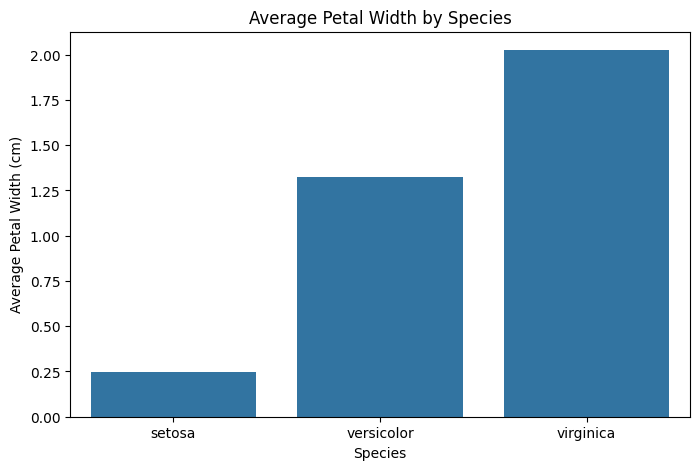

In [55]:
# Write your code here to create visualization
plt.figure(figsize=(8, 5))
sns.barplot(x='species', y='petal_width', data=avg_petal_width)
plt.title('Average Petal Width by Species')
plt.xlabel('Species')
plt.ylabel('Average Petal Width (cm)')
plt.show()

**Q9. print the correlation matrix of all numeric features and visualize it in heatmap.**
- format:
```
              sepal_length  sepal_width  petal_length  petal_width
sepal_length      -               -           -             -
sepal_width       -               -           -             -
petal_length      -               -           -             -
petal_width       -               -           -             -
```

In [56]:
# Write your code here
correlation_matrix = data[['sepal_length', 'sepal_width', 'petal_length', 'petal_width']].corr()
print(correlation_matrix)

              sepal_length  sepal_width  petal_length  petal_width
sepal_length      1.000000    -0.117570      0.871754     0.817941
sepal_width      -0.117570     1.000000     -0.428440    -0.366126
petal_length      0.871754    -0.428440      1.000000     0.962865
petal_width       0.817941    -0.366126      0.962865     1.000000


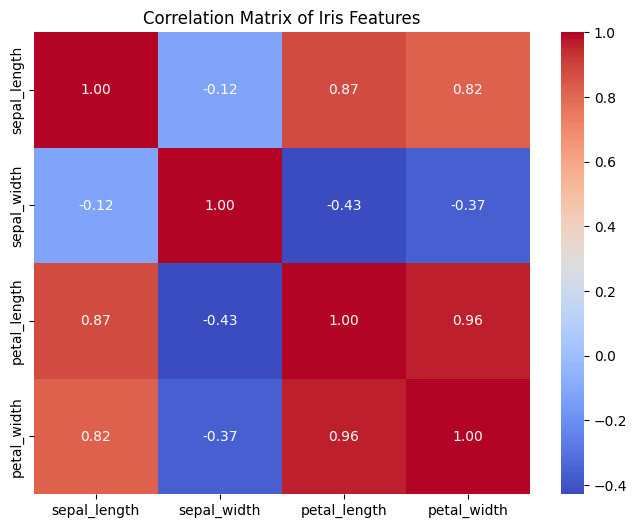

In [57]:
# Write your code here to create visualization
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Iris Features')
plt.show()

**Q10. What is the average sepal length for each species.**
- Format:
```
      species  sepal_length
0      setosa         -
1  versicolor         -
2   virginica         -
```

In [58]:
# Write your code here
grouped_avg = data.groupby('species')['sepal_length'].mean().reset_index()
print(grouped_avg)

      species  sepal_length
0      setosa         5.006
1  versicolor         5.936
2   virginica         6.588


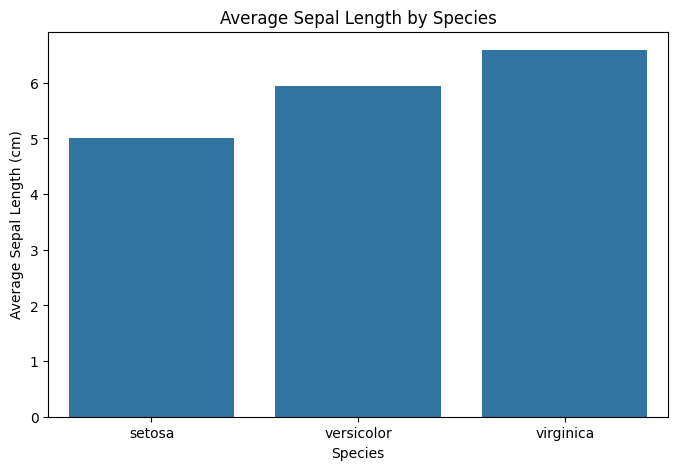

In [59]:
# Write your code here to create visualization
plt.figure(figsize=(8, 5))
sns.barplot(x='species', y='sepal_length', data=grouped_avg)
plt.title('Average Sepal Length by Species')
plt.xlabel('Species')
plt.ylabel('Average Sepal Length (cm)')
plt.show()

# End!